<a href="https://colab.research.google.com/github/Vishali-Vivek006/Engineering-employability-prediction/blob/main/notebooks/01_data_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

# Upload your engineering dataset
uploaded = files.upload()

# Identify the uploaded CSV file
csv_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload a valid CSV dataset.")

filename = csv_files[0]

# Load the dataset
df = pd.read_csv(filename)

print("=" * 70)
print("ENGINEERING EMPLOYABILITY DATASET")
print("=" * 70)

print("Dataset filename:", filename)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Saving Employability_dataset.csv to Employability_dataset.csv
ENGINEERING EMPLOYABILITY DATASET
Dataset filename: Employability_dataset.csv
Number of rows: 5000
Number of columns: 157


,Student_ID,Data_Source,Education_Level,UG_Degree,PG_Specialization,UG_Required,PG_Required_For_Target_Role,Relevant_Degree_Required,Branch,Year,...,Certification_Count,Relevant_Certification_Count,Open_Source_Contribution,Communication,Teamwork,Leadership,Problem_Solving,Presentation,Time_Management,Placement_Status
0,SYN_00001,Synthetic,UG,B.Tech Mechanical,NaN,1,1,1,Mechanical,4,...,0,0,0,43.5,79.4,59.0,48.1,46.3,63.0,0
1,SYN_00002,Synthetic,UG,B.Tech IT,NaN,1,0,0,IT,4,...,6,6,0,78.1,83.4,54.1,71.2,48.5,62.5,0
2,SYN_00003,Synthetic,UG,B.Tech Mechanical,NaN,1,0,0,Mechanical,3,...,3,3,0,61.7,52.2,47.3,48.0,67.2,49.6,1
3,SYN_00004,Synthetic,UG,B.Tech EEE,NaN,1,0,1,EEE,3,...,1,1,0,64.1,65.3,43.6,56.4,76.9,62.8,0
4,SYN_00005,Synthetic,UG,B.Tech CSE,NaN,1,0,0,CSE,3,...,3,2,0,66.7,43.5,22.7,62.2,52.6,65.2,1


In [2]:
print("ALL COLUMN NAMES")
print("=" * 70)

for i, col in enumerate(df.columns, start=1):
    print(f"{i:3}. {col}")

print("\nDATA TYPES")
print("=" * 70)

display(
    pd.DataFrame({
        "Column": df.columns,
        "Data_Type": df.dtypes.astype(str).values,
        "Unique_Values": [
            df[col].nunique(dropna=True) for col in df.columns
        ]
    })
)

ALL COLUMN NAMES
  1. Student_ID
  2. Data_Source
  3. Education_Level
  4. UG_Degree
  5. PG_Specialization
  6. UG_Required
  7. PG_Required_For_Target_Role
  8. Relevant_Degree_Required
  9. Branch
 10. Year
 11. CGPA
 12. Attendance_Percentage
 13. Backlogs
 14. Core_Subject_Score
 15. Technical_Subject_Score
 16. Aptitude_Score
 17. C
 18. Cpp
 19. Java
 20. Python
 21. JavaScript
 22. TypeScript
 23. CSharp
 24. R
 25. Go
 26. Kotlin
 27. PHP
 28. Ruby
 29. Swift
 30. Dart
 31. MATLAB
 32. DSA
 33. OOP
 34. DBMS
 35. Operating_Systems
 36. Computer_Networks
 37. Computer_Architecture
 38. Software_Engineering
 39. Computer_Security
 40. Cloud_Computing
 41. Distributed_Systems
 42. Compiler_Design
 43. Theory_of_Computation
 44. HTML
 45. CSS
 46. React
 47. Angular
 48. Vue
 49. NodeJS
 50. ExpressJS
 51. NextJS
 52. Spring_Boot
 53. Django
 54. Flask
 55. REST_API
 56. GraphQL
 57. Web_Development
 58. SQL
 59. MySQL
 60. PostgreSQL
 61. Oracle
 62. MongoDB
 63. Redis
 64. Fire

,Column,Data_Type,Unique_Values
0,Student_ID,object,5000
1,Data_Source,object,1
2,Education_Level,object,2
3,UG_Degree,object,6
4,PG_Specialization,object,5
...,...,...,...
152,Leadership,float64,661
153,Problem_Solving,float64,587
154,Presentation,float64,618
155,Time_Management,float64,533


In [3]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

print("MISSING VALUE REPORT")
display(missing[missing["Missing_Count"] > 0])

print("\nTotal missing cells:", df.isnull().sum().sum())
print("Columns with missing values:",
      (df.isnull().sum() > 0).sum())

MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
PG_Specialization,4125,82.5



Total missing cells: 4125
Columns with missing values: 1


In [4]:
print("DUPLICATE RECORD ANALYSIS")
print("=" * 70)

print("Exact duplicate rows:", df.duplicated().sum())

# Check duplicate student identifiers if available
id_candidates = [
    col for col in df.columns
    if col.strip().lower() in [
        "student_id", "studentid", "student id"
    ]
]

for col in id_candidates:
    print(f"\nIdentifier column: {col}")
    print("Missing identifiers:", df[col].isnull().sum())
    print("Unique identifiers:", df[col].nunique())
    print("Repeated identifier rows:",
          df[col].duplicated().sum())

DUPLICATE RECORD ANALYSIS
Exact duplicate rows: 0

Identifier column: Student_ID
Missing identifiers: 0
Unique identifiers: 5000
Repeated identifier rows: 0


In [5]:
print("TARGET VARIABLE INSPECTION")
print("=" * 70)

target_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "placement_status",
        "placement",
        "employability",
        "employment_status"
    ])
]

print("Potential target columns:", target_candidates)

if "Placement_Status" in df.columns:
    target_col = "Placement_Status"

    print("\nSelected target:", target_col)
    print("\nTarget values:")
    display(df[target_col].value_counts(dropna=False))

    print("\nTarget distribution (%):")
    display(
        (df[target_col].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )

    print("\nUnique target labels:",
          df[target_col].dropna().unique())
else:
    target_col = None
    print(
        "\nPlacement_Status was not found. "
        "Inspect the potential target columns above before choosing one."
    )

TARGET VARIABLE INSPECTION
Potential target columns: ['Placement_Status']

Selected target: Placement_Status

Target values:


,count
Placement_Status,
0,2872
1,2128



Target distribution (%):


,proportion
Placement_Status,
0,57.44
1,42.56



Unique target labels: [0 1]


In [6]:
print("NUMERICAL FEATURES")
print("=" * 70)

numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Number of numerical columns:", len(numeric_cols))

if numeric_cols:
    display(df[numeric_cols].describe().T)

print("\nCATEGORICAL FEATURES")
print("=" * 70)

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_cols))

for col in categorical_cols:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique(dropna=True))
    print("Examples:",
          df[col].dropna().astype(str).unique()[:10])

NUMERICAL FEATURES
Number of numerical columns: 151


,count,mean,std,min,25%,50%,75%,max
UG_Required,5000.0,1.000000,0.000000,1.0,1.00,1.00,1.000,1.0
PG_Required_For_Target_Role,5000.0,0.127200,0.333230,0.0,0.00,0.00,0.000,1.0
Relevant_Degree_Required,5000.0,0.555200,0.496993,0.0,0.00,1.00,1.000,1.0
Year,5000.0,3.650600,0.476828,3.0,3.00,4.00,4.000,4.0
CGPA,5000.0,7.728904,0.850024,5.2,7.14,7.72,8.310,10.0
...,...,...,...,...,...,...,...,...
Leadership,5000.0,53.700240,13.439659,15.0,44.50,53.50,63.100,100.0
Problem_Solving,5000.0,60.495320,11.161704,20.0,52.90,60.50,68.100,100.0
Presentation,5000.0,54.932600,12.069931,20.0,47.00,54.90,63.025,100.0
Time_Management,5000.0,59.931040,10.139706,21.2,53.20,59.80,66.800,96.3



CATEGORICAL FEATURES
Number of categorical columns: 6

Student_ID
Unique values: 5000
Examples: ['SYN_00001' 'SYN_00002' 'SYN_00003' 'SYN_00004' 'SYN_00005' 'SYN_00006'
 'SYN_00007' 'SYN_00008' 'SYN_00009' 'SYN_00010']

Data_Source
Unique values: 1
Examples: ['Synthetic']

Education_Level
Unique values: 2
Examples: ['UG' 'PG']

UG_Degree
Unique values: 6
Examples: ['B.Tech Mechanical' 'B.Tech IT' 'B.Tech EEE' 'B.Tech CSE' 'B.Tech Civil'
 'B.Tech ECE']

PG_Specialization
Unique values: 5
Examples: ['M.Sc' 'M.E.' 'MBA' 'M.Tech' 'MCA']

Branch
Unique values: 6
Examples: ['Mechanical' 'IT' 'EEE' 'CSE' 'Civil' 'ECE']


In [7]:
missing_tokens = {
    "", "na", "n/a", "nan", "none",
    "null", "unknown", "not available"
}

print("POSSIBLE TEXT MISSING VALUES")
print("=" * 70)

for col in df.select_dtypes(include=["object"]).columns:
    values = df[col].astype("string").str.strip().str.lower()
    count = values.isin(missing_tokens).sum()

    if count > 0:
        print(f"{col}: {count} possible missing-value entries")

POSSIBLE TEXT MISSING VALUES


Department distribution:


,count
Branch,
CSE,1644
IT,901
ECE,798
Mechanical,692
Civil,493
EEE,472


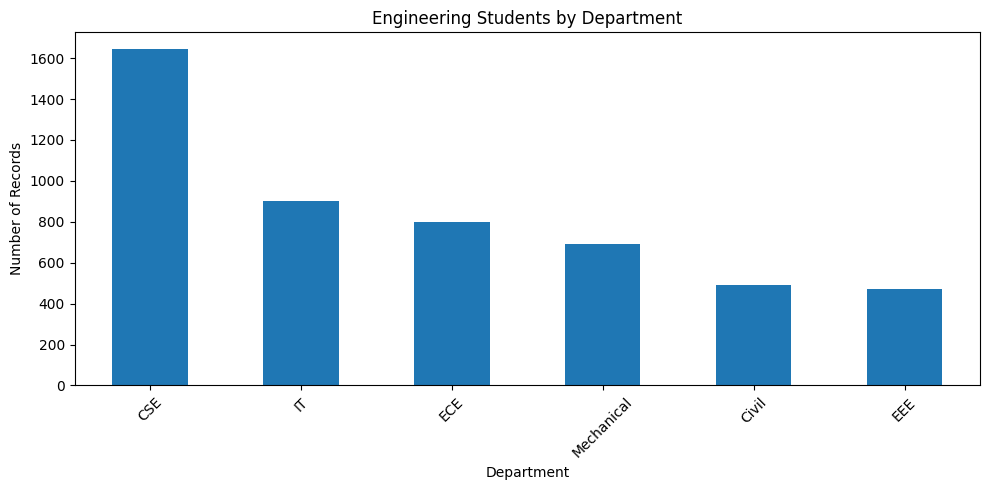

In [8]:
branch_candidates = [
    col for col in df.columns
    if col.strip().lower() in [
        "branch", "department", "engineering_branch"
    ]
]

if branch_candidates:
    branch_col = branch_candidates[0]

    print("Department distribution:")
    display(df[branch_col].value_counts(dropna=False))

    df[branch_col].value_counts().plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Engineering Students by Department")
    plt.xlabel("Department")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No recognizable department column found.")

In [9]:
print("POTENTIAL LEAKAGE AND IDENTIFIER REVIEW")
print("=" * 70)

for col in df.columns:
    name = col.lower()

    if (
        "student_id" in name
        or name in ["id", "placement_status"]
        or "placed_company" in name
        or "placement_date" in name
        or "offer_letter" in name
    ):
        print("Review before model training:", col)

POTENTIAL LEAKAGE AND IDENTIFIER REVIEW
Review before model training: Student_ID
Review before model training: Placement_Status


In [10]:
summary = {
    "Dataset": filename,
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Exact_Duplicate_Rows": int(df.duplicated().sum()),
    "Missing_Cells": int(df.isnull().sum().sum()),
    "Columns_With_Missing_Values": int(
        (df.isnull().sum() > 0).sum()
    ),
    "Numerical_Columns": len(numeric_cols),
    "Categorical_Columns": len(categorical_cols),
    "Target_Column": target_col
}

print("FINAL PHASE 1 SUMMARY")
display(pd.DataFrame([summary]).T.rename(
    columns={0: "Value"}
))

FINAL PHASE 1 SUMMARY


,Value
Dataset,Employability_dataset.csv
Rows,5000
Columns,157
Exact_Duplicate_Rows,0
Missing_Cells,4125
Columns_With_Missing_Values,1
Numerical_Columns,151
Categorical_Columns,6
Target_Column,Placement_Status
